# Classificação da qualidade de vinhos

**Objetivo:** prever se um vinho é de alta qualidade (nota ≥ 7) a partir de
suas características físico-químicas.

**Variável alvo:** `qualidade_alta` (1 = nota ≥ 7, 0 = nota < 7).

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

## 1. Compreensão do problema

In [2]:
df = pd.read_csv("../data/Base.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
len(df)

1143

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


### Primeiras observações

- 1.143 amostras, 11 variáveis físico-químicas, sem valores nulos.
- A coluna `Id` é apenas identificador e não será usada no modelo.
- A coluna `quality` não será usada como entrada, pois dela deriva o alvo.

In [6]:
df["qualidade_alta"] = (df["quality"] >= 7).astype(int)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,qualidade_alta
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4,0


In [7]:
print(df["qualidade_alta"].value_counts())
print(df["qualidade_alta"].value_counts(normalize=True).round(3))

qualidade_alta
0    984
1    159
Name: count, dtype: int64
qualidade_alta
0    0.861
1    0.139
Name: proportion, dtype: float64


In [8]:
df.groupby("quality")["qualidade_alta"].agg(["count", "min", "max"])

,count,min,max
quality,,,
3,6,0,0
4,33,0,0
5,483,0,0
6,462,0,0
7,143,1,1
8,16,1,1


## 2. Análise Exploratória

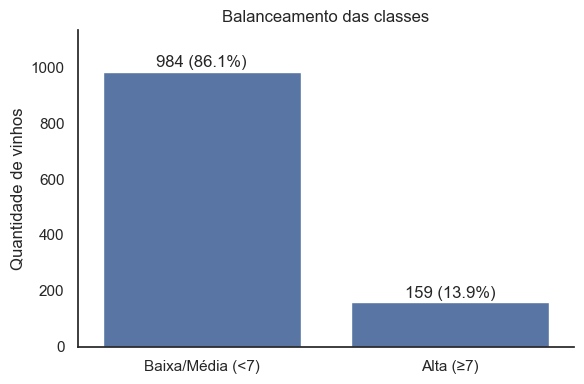

In [9]:
sns.set_theme(style="white")

contagem = df["qualidade_alta"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Baixa/Média (<7)", "Alta (≥7)"], y=contagem.values, ax=ax)

for i, v in enumerate(contagem.values):
    ax.text(i, v + 15, f"{v} ({v/len(df):.1%})", ha="center")

ax.set_ylim(0, contagem.max() * 1.15)
ax.set_title("Balanceamento das classes")
ax.set_ylabel("Quantidade de vinhos")
sns.despine()

plt.tight_layout()
plt.savefig("../results/01_balanceamento_classes.png", dpi=150)
plt.show()


**Insight:** apenas 13,9% dos vinhos (159 de 1.143) são de alta qualidade.
As classes são desbalanceadas, então a acurácia sozinha não será uma boa
métrica: um modelo que classificasse todos os vinhos como "baixa/média"
acertaria 86% e não serviria para nada.

In [10]:
features = [c for c in df.columns if c not in ["Id", "quality", "qualidade_alta"]]
print(len(features), "variáveis:")
features

11 variáveis:


['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol']

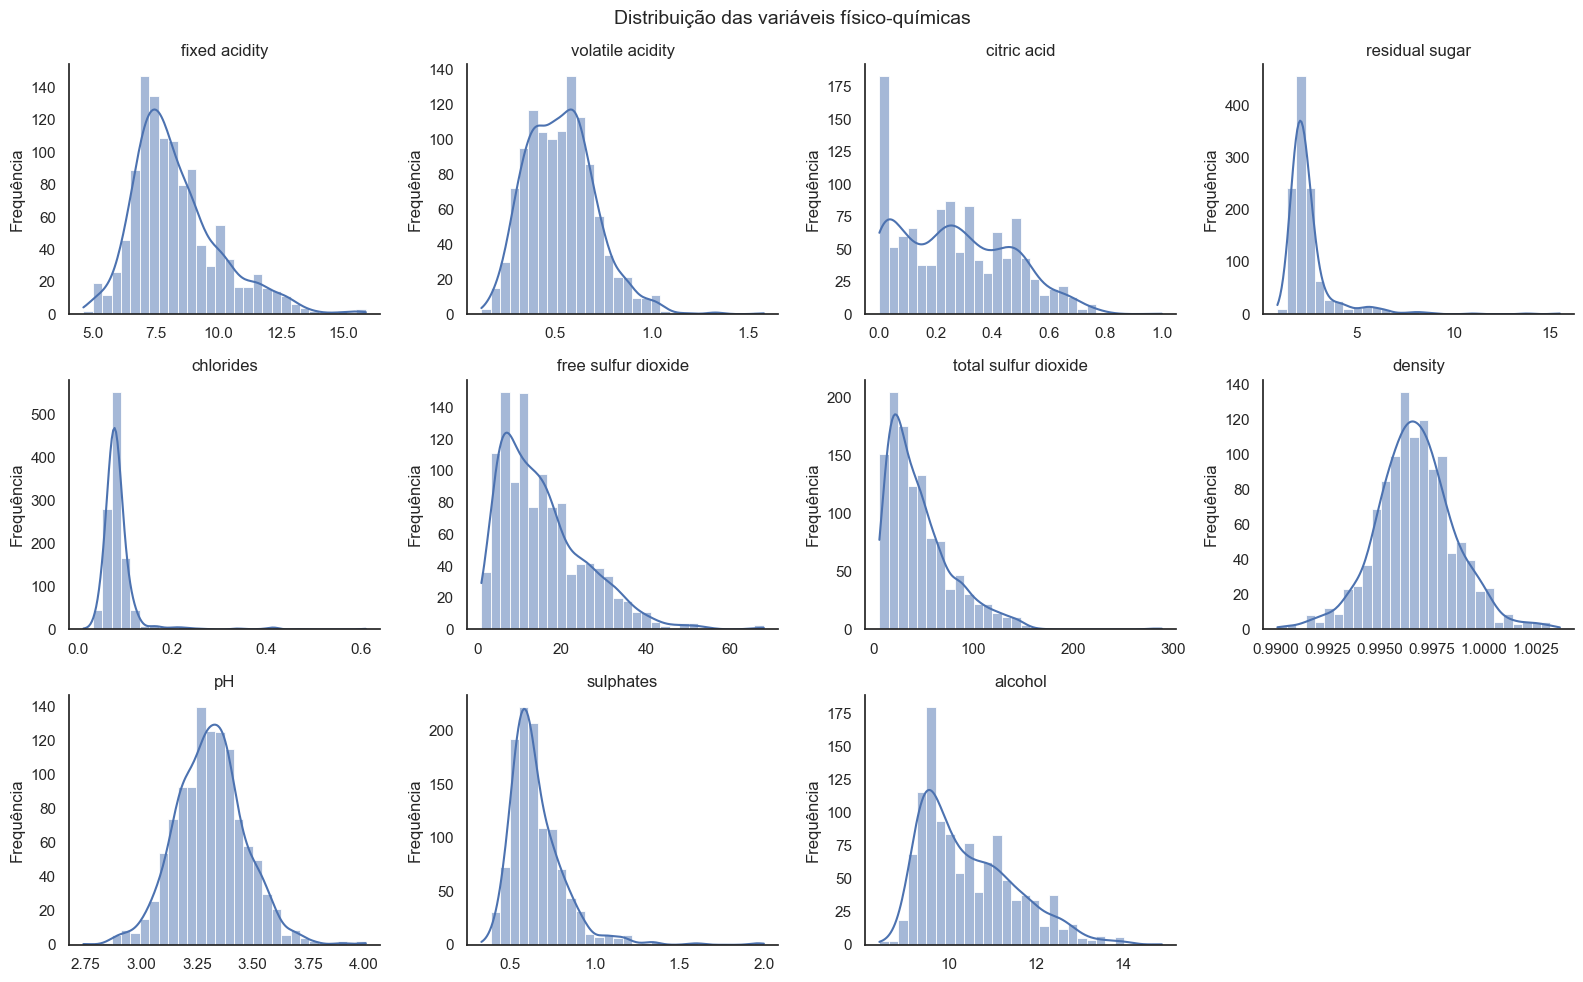

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequência")

axes[-1].set_visible(False)

sns.despine()
fig.suptitle("Distribuição das variáveis físico-químicas", fontsize=14)
plt.tight_layout()
plt.savefig("../results/02_distribuicoes.png", dpi=150)
plt.show()

In [12]:
assimetria = df[features].skew().sort_values(ascending=False).round(2)
assimetria

chlorides               6.03
residual sugar          4.36
sulphates               2.50
total sulfur dioxide    1.67
free sulfur dioxide     1.23
fixed acidity           1.04
alcohol                 0.86
volatile acidity        0.68
citric acid             0.37
pH                      0.22
density                 0.10
dtype: float64

In [13]:
(df["citric acid"] == 0).sum()

np.int64(99)

**Insight:**
- `pH` e `density` têm distribuição aproximadamente simétrica (assimetria < 0,25).
- `chlorides` (6,03), `residual sugar` (4,36), `sulphates` (2,50) e
  `total sulfur dioxide` (1,67) têm cauda longa à direita: a maioria dos
  vinhos concentra-se numa faixa estreita e poucos apresentam valores muito altos.
- `citric acid` tem 99 vinhos (8,7%) com valor exatamente zero, formando um
  pico isolado, e várias concentrações ao longo da faixa, o que sugere
  diferentes práticas de produção.
- As variáveis estão em escalas muito diferentes (ex.: `density` ≈ 1 e
  `total sulfur dioxide` até ~290), o que exigirá padronização antes de
  modelos baseados em distância, como o KNN.
- As variáveis com cauda longa são candidatas a transformação logarítmica,
  decisão que será tomada na etapa de pré-processamento.

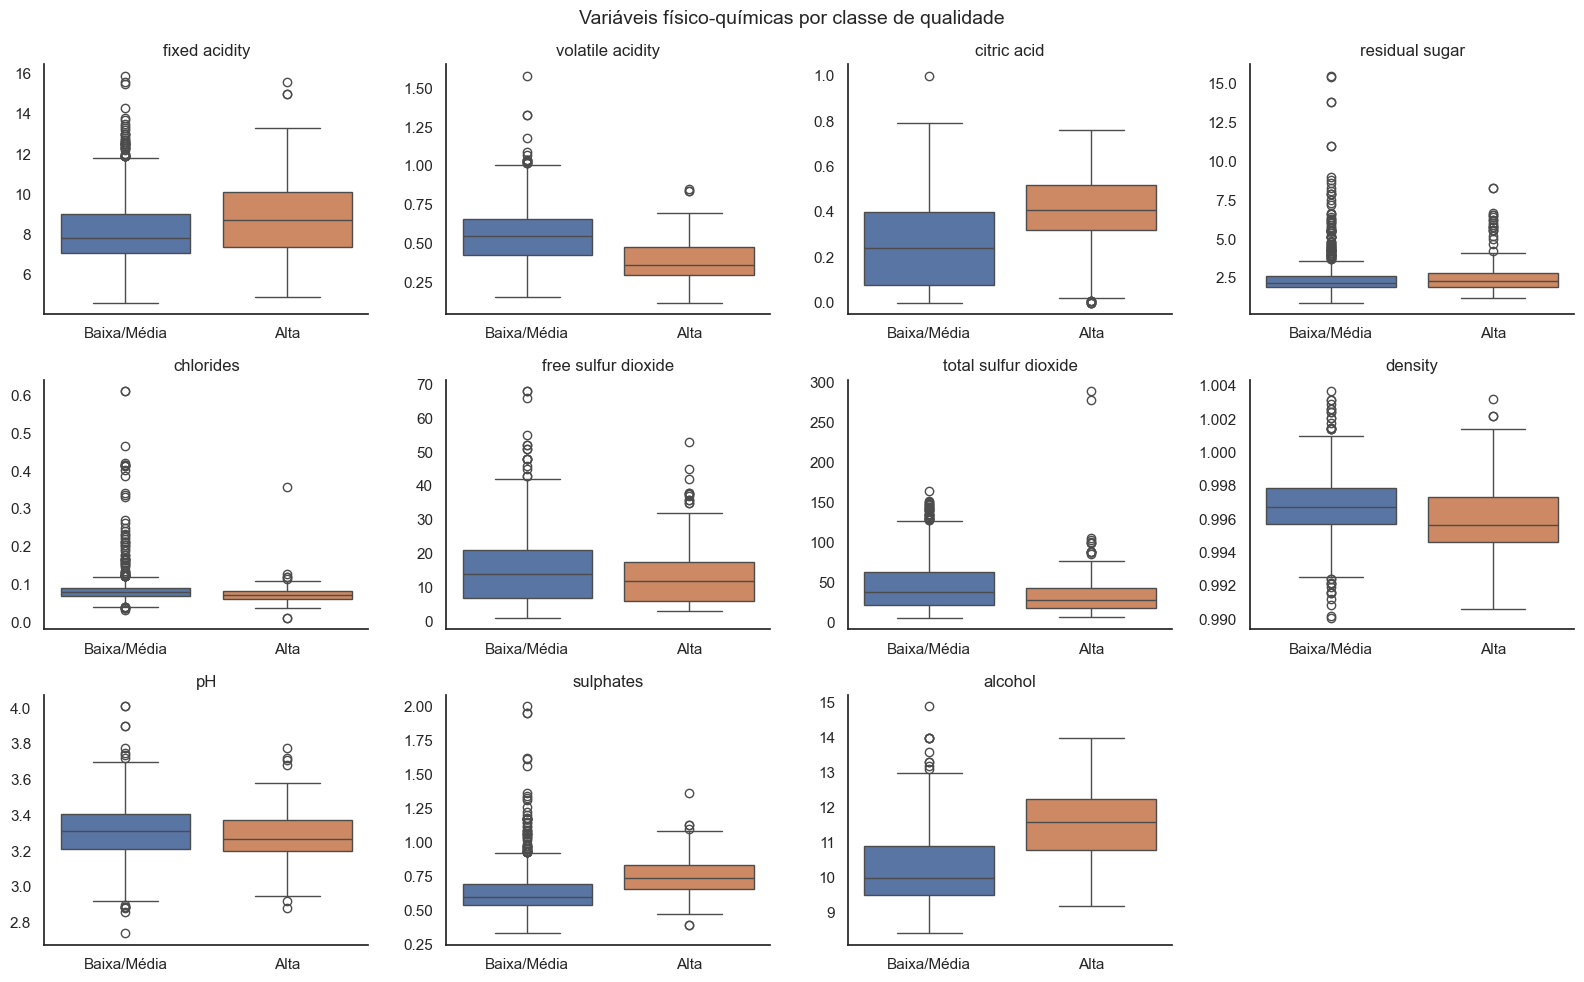

In [14]:
dados = df.assign(classe=df["qualidade_alta"].map({0: "Baixa/Média", 1: "Alta"}))

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=dados, x="classe", y=col, hue="classe",
                order=["Baixa/Média", "Alta"], legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

axes[-1].set_visible(False)

sns.despine()
fig.suptitle("Variáveis físico-químicas por classe de qualidade", fontsize=14)
plt.tight_layout()
plt.savefig("../results/03_boxplots_por_classe.png", dpi=150)
plt.show()

In [15]:
comparacao = df.groupby("qualidade_alta")[features].median().T
comparacao.columns = ["Baixa/Média", "Alta"]
comparacao["Diferença %"] = ((comparacao["Alta"] / comparacao["Baixa/Média"] - 1) * 100).round(1)
comparacao.sort_values("Diferença %", key=abs, ascending=False).round(3)

,Baixa/Média,Alta,Diferença %
citric acid,0.240,0.410,70.8
volatile acidity,0.550,0.360,-34.5
total sulfur dioxide,39.000,28.000,-28.2
sulphates,0.600,0.740,23.3
alcohol,10.000,11.600,16.0
free sulfur dioxide,14.000,12.000,-14.3
fixed acidity,7.800,8.700,11.5
chlorides,0.080,0.073,-8.8
residual sugar,2.200,2.300,4.5
pH,3.315,3.270,-1.4


**Insight:**
- As variáveis que mais diferenciam vinhos de alta qualidade dos demais são
  `alcohol` (mediana 11,6 vs 10,0), `volatile acidity` (0,36 vs 0,55),
  `citric acid` (0,41 vs 0,24) e `sulphates` (0,74 vs 0,60).
- `total sulfur dioxide`, `fixed acidity` e `density` apresentam separação
  moderada. Em `density`, a diferença percentual é pequena (-0,1%), mas
  relevante, pois a variável opera numa faixa muito estreita.
- `residual sugar`, `pH`, `chlorides` e `free sulfur dioxide` têm
  distribuições bastante sobrepostas entre as classes e, isoladamente,
  discriminam pouco.
- Vinhos de alta qualidade tendem a ter mais álcool, mais sulfatos e mais
  ácido cítrico, e menos acidez volátil e menos dióxido de enxofre total.
- Essas relações são associações, não prova de causa; serão
  confirmadas na análise de correlação e na importância das variáveis.

In [16]:
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

mask = (df[features] < limite_inf) | (df[features] > limite_sup)

resumo = pd.DataFrame({
    "outliers": mask.sum(),
    "% da base": (mask.mean() * 100).round(1)
}).sort_values("outliers", ascending=False)
resumo

,outliers,% da base
residual sugar,110,9.6
chlorides,77,6.7
fixed acidity,44,3.8
sulphates,43,3.8
total sulfur dioxide,40,3.5
density,36,3.1
pH,20,1.7
free sulfur dioxide,18,1.6
volatile acidity,14,1.2
alcohol,12,1.0


In [17]:
tem_outlier = mask.any(axis=1)

print("Vinhos com pelo menos um outlier:", tem_outlier.sum(),
      f"({tem_outlier.mean():.1%})")

pd.crosstab(df["qualidade_alta"], tem_outlier, normalize="index").round(3)

Vinhos com pelo menos um outlier: 295 (25.8%)


col_0,False,True
qualidade_alta,,
0,0.755,0.245
1,0.660,0.340


In [18]:
print("Dióxido de enxofre livre > total:",
      (df["free sulfur dioxide"] > df["total sulfur dioxide"]).sum())

print("\nValores menores ou iguais a zero, por variável:")
(df[features] <= 0).sum()

Dióxido de enxofre livre > total: 0

Valores menores ou iguais a zero, por variável:


fixed acidity            0
volatile acidity         0
citric acid             99
residual sugar           0
chlorides                0
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       0
sulphates                0
alcohol                  0
dtype: int64

In [19]:
for col in ["total sulfur dioxide", "chlorides", "sulphates", "residual sugar"]:
    print(f"\n=== 3 maiores valores de {col} ===")
    display(df.nlargest(3, col)[["Id", col, "quality"]])


=== 3 maiores valores de total sulfur dioxide ===


,Id,total sulfur dioxide,quality
761,1081,289.0,7
760,1079,278.0,7
249,354,165.0,6



=== 3 maiores valores de chlorides ===


,Id,chlorides,quality
182,258,0.611,5
103,151,0.610,4
75,106,0.467,5



=== 3 maiores valores de sulphates ===


,Id,sulphates,quality
103,151,2.00,4
59,86,1.95,6
64,91,1.95,6



=== 3 maiores valores de residual sugar ===


,Id,residual sugar,quality
339,480,15.5,5
1022,1434,15.4,6
1051,1474,13.8,5


**Insight:**
- Pela regra do IQR, 295 vinhos (25,8%) têm ao menos um outlier. As variáveis
  mais afetadas são `residual sugar` (9,6%) e `chlorides` (6,7%), coerente
  com as caudas longas observadas nas distribuições.
- Não há valores impossíveis: o dióxido de enxofre livre nunca excede o total
  e os únicos zeros estão em `citric acid`, o que é plausível. Os outliers
  são, portanto, valores extremos e não erros de registro evidentes.
- Os outliers se concentram mais na classe de alta qualidade (34,0% dos
  vinhos contra 24,5%), o que sugere que esses vinhos têm perfil
  físico-químico distinto. Removê-los eliminaria cerca de um terço da classe
  minoritária.
- Os casos mais suspeitos são dois vinhos de nota 7 com dióxido de enxofre
  total de 289 e 278, muito acima do terceiro maior valor (165).
- Decisão preliminar: não remover outliers em massa. Avaliar transformação
  logarítmica e padronização robusta na etapa de pré-processamento, e testar
  o impacto dos dois casos extremos de enxofre total.

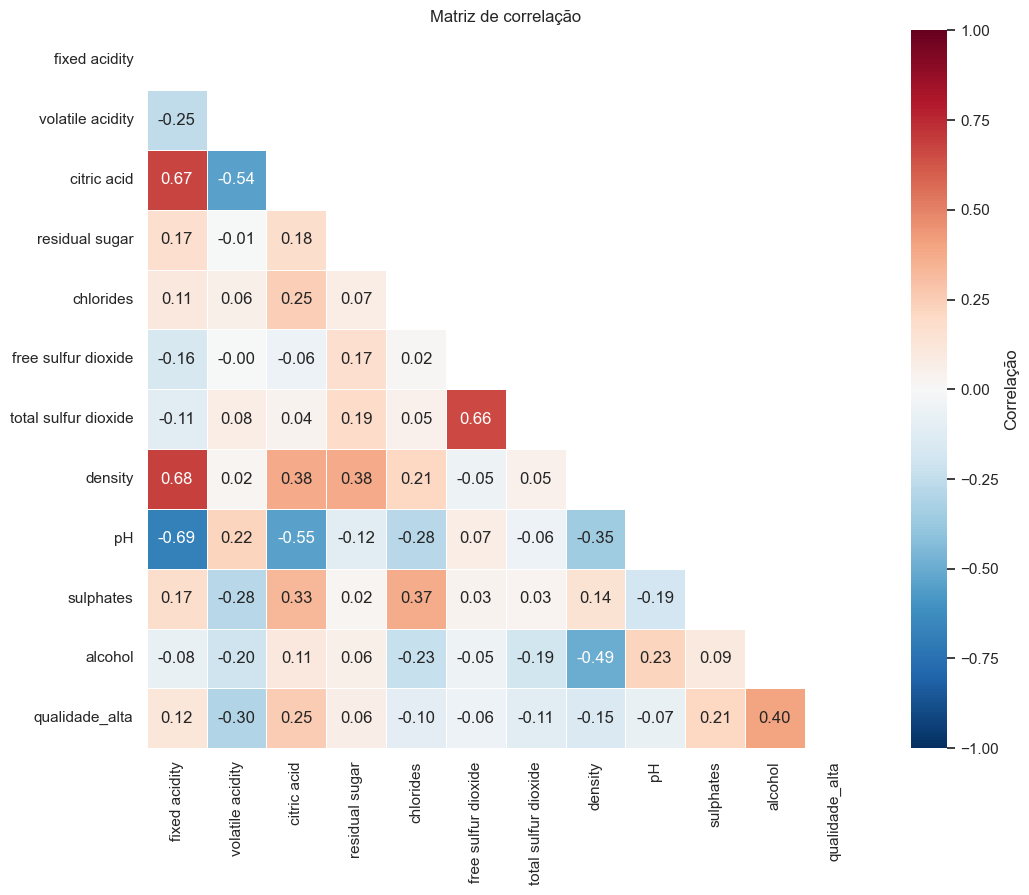

In [20]:
corr = df[features + ["qualidade_alta"]].corr()

mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, cbar_kws={"label": "Correlação"}, ax=ax)

ax.set_title("Matriz de correlação")
plt.tight_layout()
plt.savefig("../results/04_heatmap_correlacao.png", dpi=150)
plt.show()

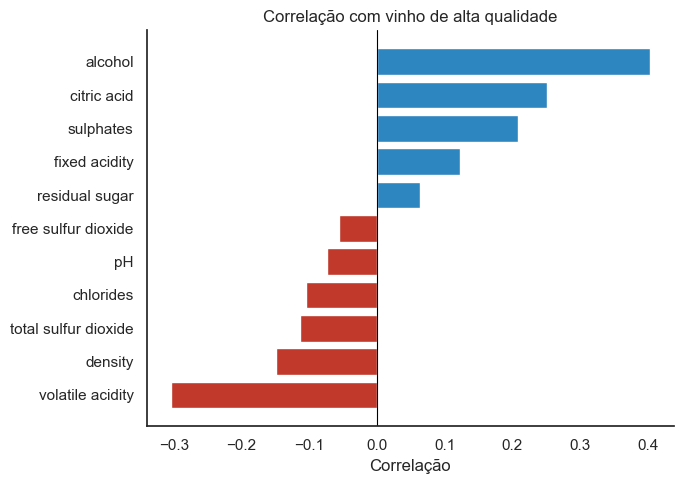

In [21]:
corr_alvo = corr["qualidade_alta"].drop("qualidade_alta").sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
cores = ["#c0392b" if v < 0 else "#2e86c1" for v in corr_alvo]
ax.barh(corr_alvo.index, corr_alvo.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlação com vinho de alta qualidade")
ax.set_xlabel("Correlação")
sns.despine()
plt.tight_layout()
plt.savefig("../results/05_correlacao_com_alvo.png", dpi=150)
plt.show()

In [22]:
pares = (corr.drop(index="qualidade_alta", columns="qualidade_alta")
             .where(~mascara[:-1, :-1])
             .stack()
             .rename("correlação")
             .reset_index())
pares.columns = ["variável 1", "variável 2", "correlação"]
pares["abs"] = pares["correlação"].abs()
pares.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(2)

,variável 1,variável 2,correlação
28,pH,fixed acidity,-0.69
21,density,fixed acidity,0.68
1,citric acid,fixed acidity,0.67
20,total sulfur dioxide,free sulfur dioxide,0.66
30,pH,citric acid,-0.55
2,citric acid,volatile acidity,-0.54
52,alcohol,density,-0.49
24,density,residual sugar,0.38


**Insight: correlação com a qualidade**
- `alcohol` é a variável mais associada a vinhos de alta qualidade (+0,40):
  vinhos com mais álcool tendem a ser mais bem avaliados.
- `volatile acidity` tem a maior associação negativa (-0,30): vinhos com mais
  acidez volátil tendem a ter nota menor.
- `citric acid` (+0,25) e `sulphates` (+0,21) também se associam
  positivamente à qualidade alta.
- Nenhuma variável passa de 0,5 em módulo: nenhuma sozinha explica a
  qualidade, o que sugere que o modelo precisará combinar várias variáveis.
- Correlação indica associação, não causa.

**Insight: correlação entre as variáveis**
- `fixed acidity` × `pH` (-0,69): o pH mede a acidez, então mais ácido
  significa pH menor.
- `fixed acidity` × `density` (+0,68): vinhos com mais ácidos tendem a ser
  mais densos.
- `fixed acidity` × `citric acid` (+0,67): o ácido cítrico faz parte da
  acidez fixa.
- `free` × `total sulfur dioxide` (+0,66): o enxofre livre é uma parte do
  total.
- `citric acid` × `pH` (-0,55): o ácido cítrico é um ácido, logo reduz o pH.
- `citric acid` × `volatile acidity` (-0,54): vinhos com mais ácido cítrico
  tendem a ter menos acidez volátil (padrão observado, sem explicação direta).
- `alcohol` × `density` (-0,49): o álcool é mais leve que a água, então mais
  álcool significa menor densidade.
- `density` × `residual sugar` (+0,38): o açúcar aumenta a densidade.
- Várias variáveis carregam informação parecida (acidez, pH, densidade e
  enxofre). Isso será considerado no pré-processamento e na escolha dos modelos.

In [23]:
colunas_vinho = features + ["quality"]

duplicadas = df.duplicated(subset=colunas_vinho, keep="first")
print("Linhas duplicadas:", duplicadas.sum(), f"({duplicadas.mean():.1%} da base)")

Linhas duplicadas: 125 (10.9% da base)


In [24]:
grupos = df[df.duplicated(subset=colunas_vinho, keep=False)]
grupos.sort_values(colunas_vinho).head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,qualidade_alta
96,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,142,0
98,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,144,0
949,6.0,0.50,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,1336,0
950,6.0,0.50,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,1337,0
951,6.0,0.50,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,1338,0
999,6.0,0.51,0.00,2.1,0.064,40.0,54.0,0.99500,3.54,0.93,10.7,6,1407,0
1001,6.0,0.51,0.00,2.1,0.064,40.0,54.0,0.99500,3.54,0.93,10.7,6,1409,0
517,6.4,0.57,0.02,1.8,0.067,4.0,11.0,0.99700,3.46,0.68,9.5,5,727,0
518,6.4,0.57,0.02,1.8,0.067,4.0,11.0,0.99700,3.46,0.68,9.5,5,728,0
603,6.4,0.64,0.21,1.8,0.081,14.0,31.0,0.99689,3.59,0.66,9.8,5,846,0


In [25]:
df_sem_dup = df[~duplicadas]

print("Antes: ", len(df), "vinhos")
print("Depois:", len(df_sem_dup), "vinhos")
print()
print(df_sem_dup["qualidade_alta"].value_counts())
print(df_sem_dup["qualidade_alta"].value_counts(normalize=True).round(3))

Antes:  1143 vinhos
Depois: 1018 vinhos

qualidade_alta
0    881
1    137
Name: count, dtype: int64
qualidade_alta
0    0.865
1    0.135
Name: proportion, dtype: float64


**Insight: duplicatas**
- Ignorando a coluna `Id`, há 125 linhas duplicadas (10,9% da base),
  distribuídas em 114 grupos de vinhos repetidos. Todas têm a mesma nota de
  qualidade que a cópia original.
- Remover as duplicatas reduziria a base de 1.143 para 1.018 vinhos e a
  classe de alta qualidade de 159 para 137, sem alterar de forma relevante o
  desbalanceamento (de 13,9% para 13,5%).
- Manter as duplicatas pode inflar as métricas dos modelos, pois uma cópia do
  vinho pode cair no treino e outra no teste.

## 3. Pré-processamento

In [26]:
df_limpo = (df.drop_duplicates(subset=features + ["quality"], keep="first")
              .reset_index(drop=True))

print("Antes: ", len(df), "vinhos")
print("Depois:", len(df_limpo), "vinhos")
print("Valores nulos:", df_limpo.isna().sum().sum())
print()
print(df_limpo["qualidade_alta"].value_counts())

Antes:  1143 vinhos
Depois: 1018 vinhos
Valores nulos: 0

qualidade_alta
0    881
1    137
Name: count, dtype: int64


In [27]:
cols_log = ["chlorides", "residual sugar", "sulphates",
            "total sulfur dioxide", "free sulfur dioxide"]

df_proc = df_limpo.copy()
df_proc[cols_log] = np.log(df_proc[cols_log])

pd.DataFrame({
    "assimetria antes": df_limpo[cols_log].skew(),
    "assimetria depois": df_proc[cols_log].skew()
}).round(2)

,assimetria antes,assimetria depois
chlorides,5.93,1.83
residual sugar,4.35,1.69
sulphates,2.42,0.98
total sulfur dioxide,1.68,-0.06
free sulfur dioxide,1.17,-0.23


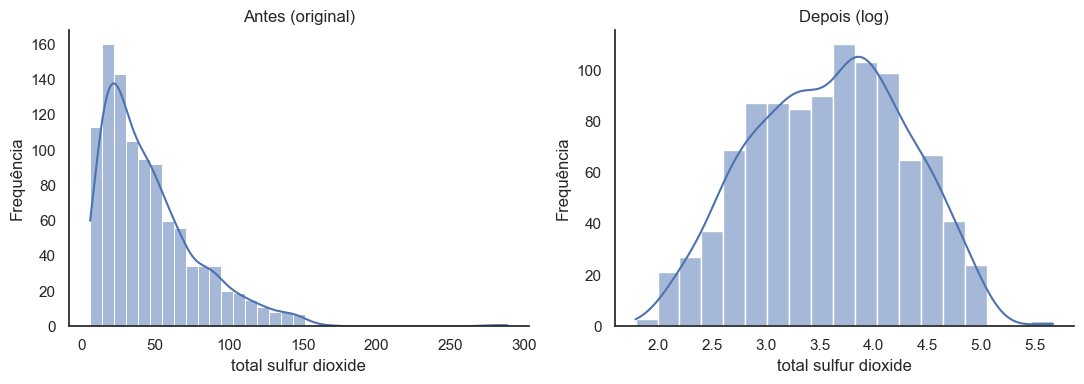

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_limpo["total sulfur dioxide"], kde=True, ax=axes[0])
axes[0].set_title("Antes (original)")
sns.histplot(df_proc["total sulfur dioxide"], kde=True, ax=axes[1])
axes[1].set_title("Depois (log)")
axes[0].set_ylabel("Frequência")
axes[1].set_ylabel("Frequência")
sns.despine()
plt.tight_layout()
plt.savefig("../results/06_efeito_log.png", dpi=150)
plt.show()

**Pré-processamento: limpeza e transformação**
- Foram removidas as 125 linhas duplicadas, resultando em 1.018 vinhos
  (881 de baixa/média qualidade e 137 de alta). Não há valores nulos,
  portanto não foi necessário tratamento de dados faltantes.
- Os outliers não foram removidos. Em vez disso, aplicou-se transformação
  logarítmica nas variáveis com cauda longa (`chlorides`, `residual sugar`,
  `sulphates`, `total sulfur dioxide` e `free sulfur dioxide`).
- A transformação reduziu a assimetria de todas essas variáveis. As duas
  variáveis de dióxido de enxofre ficaram praticamente simétricas, e
  `chlorides` caiu de 5,93 para 1,83.
- Com isso, os valores extremos (como os vinhos com 278 e 289 de dióxido de
  enxofre total) permanecem na base, mas ficam mais próximos do restante dos
  dados, sem perder informação da classe minoritária.

In [29]:
candidatas = pd.DataFrame({
    "acidez_total": df_limpo["fixed acidity"] + df_limpo["volatile acidity"] + df_limpo["citric acid"],
    "razao_acidez": df_limpo["fixed acidity"] / df_limpo["volatile acidity"],
    "razao_so2_livre": df_limpo["free sulfur dioxide"] / df_limpo["total sulfur dioxide"],
    "sulfatos_por_cloretos": np.log(df_limpo["sulphates"] / df_limpo["chlorides"]),
    "alcool_x_sulfatos": df_limpo["alcohol"] * df_limpo["sulphates"],
})

avaliacao = pd.DataFrame({
    "corr com alvo": candidatas.corrwith(df_limpo["qualidade_alta"]),
    "variável mais parecida": [df_proc[features].corrwith(candidatas[c]).abs().idxmax()
                               for c in candidatas],
    "corr com ela": [df_proc[features].corrwith(candidatas[c]).abs().max()
                     for c in candidatas],
}).round(2)

avaliacao.sort_values("corr com alvo", ascending=False)

,corr com alvo,variável mais parecida,corr com ela
alcool_x_sulfatos,0.36,sulphates,0.92
sulfatos_por_cloretos,0.32,chlorides,0.79
razao_acidez,0.31,volatile acidity,0.79
razao_so2_livre,0.13,total sulfur dioxide,0.33
acidez_total,0.10,fixed acidity,1.00


In [30]:
df_proc["sulfatos_por_cloretos"] = np.log(df_limpo["sulphates"] / df_limpo["chlorides"])
df_proc["razao_so2_livre"] = df_limpo["free sulfur dioxide"] / df_limpo["total sulfur dioxide"]

features_modelo = features + ["sulfatos_por_cloretos", "razao_so2_livre"]
print(len(features_modelo), "variáveis para o modelo")
features_modelo

13 variáveis para o modelo


['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol',
 'sulfatos_por_cloretos',
 'razao_so2_livre']

**Feature engineering**
Foram testadas 5 variáveis novas, mantendo apenas as que se relacionam com a
qualidade sem repetir uma variável existente:
- `sulfatos_por_cloretos` (mantida): relação entre conservante e sal. Correlação
  de 0,32 com a qualidade alta, maior que a de `sulphates` e `chlorides` isoladas.
- `razao_so2_livre` (mantida): fração do dióxido de enxofre que está livre.
  Correlação fraca (0,13), mas traz uma informação que nenhuma outra variável tem.
- `alcool_x_sulfatos` (descartada): quase idêntica a `sulphates` (0,92).
- `razao_acidez` (descartada): ganho desprezível sobre `volatile acidity`
  (0,31 contra 0,30).
- `acidez_total` (descartada): equivalente a `fixed acidity` (1,00).
O impacto real das variáveis novas será avaliado na importância das variáveis
do modelo.

In [31]:
X = df_proc[features_modelo]
y = df_proc["qualidade_alta"]

print("X:", X.shape)
print("y:", y.shape)

X: (1018, 13)
y: (1018,)


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Treino:", X_train.shape, "| vinhos de alta qualidade:", y_train.sum())
print("Teste: ", X_test.shape, "| vinhos de alta qualidade:", y_test.sum())
print()
print("Proporção de alta qualidade no treino:", round(y_train.mean(), 3))
print("Proporção de alta qualidade no teste: ", round(y_test.mean(), 3))

Treino: (814, 13) | vinhos de alta qualidade: 110
Teste:  (204, 13) | vinhos de alta qualidade: 27

Proporção de alta qualidade no treino: 0.135
Proporção de alta qualidade no teste:  0.132


**Separação dos dados**
- X: 13 variáveis físico-químicas (11 originais + 2 criadas). y: `qualidade_alta`.
- Divisão de 80% para treino (814 vinhos) e 20% para teste (204 vinhos).
- A divisão foi estratificada, preservando a proporção de vinhos de alta
  qualidade nos dois conjuntos (13,5% no treino e 13,2% no teste).
- O conjunto de teste contém 27 vinhos de alta qualidade e será usado apenas
  na avaliação final dos modelos.
- `random_state=42` garante que a divisão seja reproduzível.

In [33]:
scaler = StandardScaler()

X_train_esc = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns, index=X_train.index
)
X_test_esc = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns, index=X_test.index
)

X_train_esc.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,sulfatos_por_cloretos,razao_so2_livre
814,-0.762760,-0.602243,-0.429984,-0.010286,-0.413030,0.529869,-0.001852,-1.022871,0.501807,-0.622096,0.422141,0.003528,0.773132
628,0.444408,-1.304262,0.277816,-0.356560,-0.760727,0.056962,-0.403296,-0.813319,-0.310635,1.170154,1.163105,1.462174,0.653341
883,-0.417855,-1.250261,0.732830,-0.430867,-1.318842,-1.066647,-0.567656,-0.216097,0.814286,1.063637,1.348346,1.928358,-0.844046
547,1.938996,-1.358264,0.985616,-0.919930,-1.209074,0.446806,-0.166211,0.077275,-0.998087,0.170633,0.144279,1.262209,0.975280
138,-0.762760,-0.224232,1.086730,2.667534,-0.902633,1.064251,1.689807,0.360170,0.189329,0.727762,0.051658,1.319665,-1.071252


In [34]:
pd.DataFrame({
    "média treino": X_train_esc.mean(),
    "desvio treino": X_train_esc.std(),
    "média teste": X_test_esc.mean(),
    "desvio teste": X_test_esc.std(),
}).round(2)

,média treino,desvio treino,média teste,desvio teste
fixed acidity,-0.0,1.0,-0.11,1.00
volatile acidity,0.0,1.0,0.05,0.94
citric acid,0.0,1.0,-0.16,0.95
residual sugar,0.0,1.0,0.21,1.22
chlorides,-0.0,1.0,-0.11,0.78
free sulfur dioxide,-0.0,1.0,0.07,0.93
total sulfur dioxide,-0.0,1.0,0.08,0.92
density,-0.0,1.0,-0.03,1.02
pH,0.0,1.0,0.06,0.93
sulphates,0.0,1.0,-0.17,0.86


**Padronização**
- As variáveis foram padronizadas com `StandardScaler` (média 0 e desvio 1),
  para que variáveis com escalas maiores não dominem os modelos baseados em
  distância, como o KNN.
- O scaler foi ajustado apenas com os dados de treino e depois aplicado ao
  teste, evitando que informações do teste influenciem o treinamento.
- Foram mantidas duas versões dos dados: padronizada (para Regressão Logística
  e KNN) e original (para Random Forest, que não depende de escala).

## 4. Desenvolvimento dos modelos

In [35]:
modelo_base = DummyClassifier(strategy="most_frequent")
modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)

print("Acurácia:", round(accuracy_score(y_test, pred_base), 3))
print("Vinhos apostados como alta qualidade:", pred_base.sum(), "| vinhos de alta qualidade no teste:", y_test.sum())

Acurácia: 0.868
Vinhos apostados como alta qualidade: 0 | vinhos de alta qualidade no teste: 27


In [36]:
modelo_lr = LogisticRegression(max_iter=1000)
modelo_lr.fit(X_train_esc, y_train)
pred_lr = modelo_lr.predict(X_test_esc)

print("Acurácia:", round(accuracy_score(y_test, pred_lr), 3))
print("Vinhos apostados como alta qualidade:", pred_lr.sum(), "| vinhos de alta qualidade no teste:", y_test.sum())

Acurácia: 0.897
Vinhos apostados como alta qualidade: 18 | vinhos de alta qualidade no teste: 27


In [37]:
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_esc, y_train)
pred_knn = modelo_knn.predict(X_test_esc)

print("Acurácia:", round(accuracy_score(y_test, pred_knn), 3))
print("Vinhos apostados como alta qualidade:", pred_knn.sum(), "| vinhos de alta qualidade no teste:", y_test.sum())

Acurácia: 0.877
Vinhos apostados como alta qualidade: 18 | vinhos de alta qualidade no teste: 27


In [38]:
modelo_rf = RandomForestClassifier(n_estimators=300, random_state=42)
modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)

print("Acurácia:", round(accuracy_score(y_test, pred_rf), 3))
print("Vinhos apostados como alta qualidade:", pred_rf.sum(), "| vinhos de alta qualidade no teste:", y_test.sum())

Acurácia: 0.902
Vinhos apostados como alta qualidade: 15 | vinhos de alta qualidade no teste: 27


**Desenvolvimento dos modelos**
- Foram treinados três modelos: Regressão Logística, KNN (5 vizinhos) e
  Random Forest (300 árvores), além de um modelo de referência (baseline)
  que sempre prevê "baixa/média qualidade".
- Regressão Logística e KNN usam os dados padronizados; a Random Forest
  usa os dados originais.
- Pela acurácia, os modelos (0,877 a 0,902) superam o baseline (0,868) em
  poucos pontos. Como o baseline acerta 86,8% sem identificar nenhum vinho
  de alta qualidade, a acurácia não é suficiente para avaliar os modelos.
  A avaliação detalhada é feita na etapa seguinte.

## 5. Avaliação dos modelos

In [39]:
def avaliar(nome, modelo, X_teste, pred):
    prob = modelo.predict_proba(X_teste)[:, 1]
    return {
        "modelo": nome,
        "acurácia": accuracy_score(y_test, pred),
        "precisão": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "auc": roc_auc_score(y_test, prob),
    }

resultados = pd.DataFrame([
    avaliar("Baseline", modelo_base, X_test, pred_base),
    avaliar("Regressão Logística", modelo_lr, X_test_esc, pred_lr),
    avaliar("KNN", modelo_knn, X_test_esc, pred_knn),
    avaliar("Random Forest", modelo_rf, X_test, pred_rf),
]).set_index("modelo").round(3)

resultados

,acurácia,precisão,recall,f1,auc
modelo,,,,,
Baseline,0.868,0.000,0.000,0.000,0.500
Regressão Logística,0.897,0.667,0.444,0.533,0.886
KNN,0.877,0.556,0.370,0.444,0.854
Random Forest,0.902,0.733,0.407,0.524,0.910


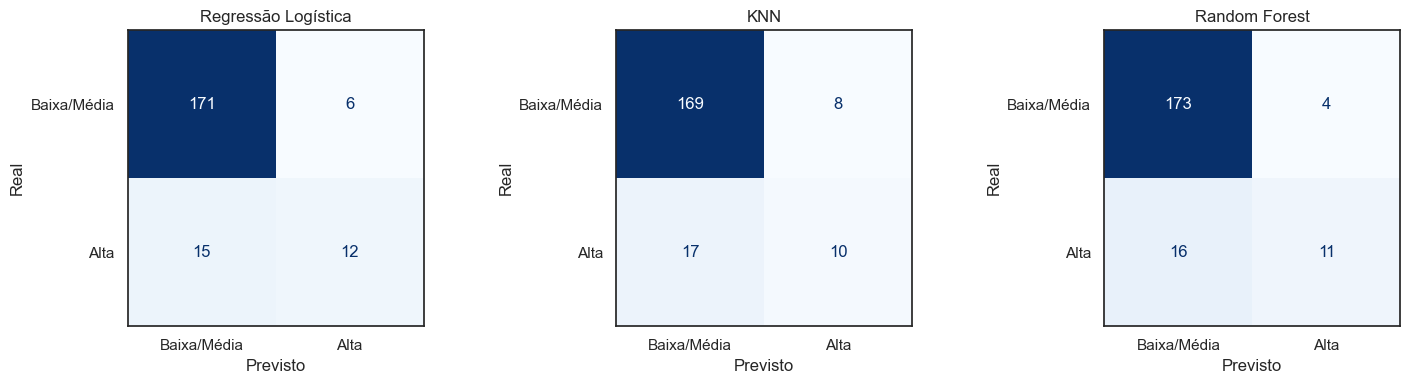

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

modelos_pred = [("Regressão Logística", pred_lr),
                ("KNN", pred_knn),
                ("Random Forest", pred_rf)]

for ax, (nome, pred) in zip(axes, modelos_pred):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Baixa/Média", "Alta"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.savefig("../results/07_matrizes_confusao.png", dpi=150)
plt.show()

**Avaliação inicial (conjunto de teste)**
- Os três modelos superam o baseline em todas as métricas que importam:
  o baseline não identifica nenhum vinho de alta qualidade.
- Os modelos são conservadores: quando apostam que um vinho é de alta
  qualidade, costumam acertar (precisão de 0,56 a 0,73), mas encontram
  menos da metade dos vinhos bons (recall de 0,37 a 0,44).
- A AUC entre 0,85 e 0,91 indica que os modelos ordenam bem os vinhos
  por probabilidade de serem de alta qualidade.

**Critério de negócio**
- O erro mais grave para a vinícola é classificar um vinho comum como
  premium (falso positivo), pois compromete a reputação da marca.
- Por isso, a precisão é priorizada. A métrica principal será o F0,5,
  que pondera mais a precisão sem ignorar o recall.
- Como o teste tem apenas 27 vinhos de alta qualidade, as métricas são
  sensíveis a poucos acertos ou erros. A comparação entre modelos será
  feita com validação cruzada no conjunto de treino.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas = {
    "precisão": "precision",
    "recall": "recall",
    "f0.5": make_scorer(fbeta_score, beta=0.5),
    "auc": "roc_auc",
}

modelos_cv = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}

linhas = []
for nome, modelo in modelos_cv.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    linha = {"modelo": nome}
    for m in metricas:
        linha[m] = r[f"test_{m}"].mean()
        linha[f"{m} (±)"] = r[f"test_{m}"].std()
    linhas.append(linha)

resultados_cv = pd.DataFrame(linhas).set_index("modelo").round(3)
resultados_cv

,precisão,precisão (±),recall,recall (±),f0.5,f0.5 (±),auc,auc (±)
modelo,,,,,,,,
Regressão Logística,0.618,0.173,0.391,0.121,0.549,0.159,0.888,0.030
KNN,0.554,0.112,0.455,0.108,0.529,0.109,0.788,0.056
Random Forest,0.564,0.134,0.282,0.078,0.468,0.114,0.867,0.032


**Validação cruzada (5 partes, somente no treino)**
- A Regressão Logística apresentou os melhores resultados médios em precisão
  (0,618), F0,5 (0,549) e AUC (0,888).
- No F0,5, porém, as variações entre as rodadas são grandes (±0,11 a ±0,16) e
  as faixas dos modelos se sobrepõem: a vantagem da Regressão Logística sobre o
  KNN não é conclusiva por essa métrica.
- Na AUC, as variações são pequenas (±0,03 a ±0,06). Regressão Logística e
  Random Forest ordenam os vinhos de forma semelhante, e o KNN fica abaixo
  (0,788).
- A Random Forest, que teve a maior precisão no conjunto de teste (0,73),
  ficou com o menor F0,5 na validação cruzada (0,468). Isso mostra que o
  resultado de um único teste com poucos vinhos de alta qualidade pode ser
  enganoso.
- Foi utilizado pipeline para que a padronização fosse ajustada apenas com os
  dados de treino de cada rodada, evitando vazamento de informação.

In [42]:
linhas_k = []
for k in range(3, 32, 2):
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    linha = {"k": k}
    for m in metricas:
        linha[m] = r[f"test_{m}"].mean()
    linhas_k.append(linha)

resultados_k = pd.DataFrame(linhas_k).set_index("k").round(3)

melhor_k = resultados_k["f0.5"].idxmax()
print("Melhor K pelo F0,5:", melhor_k)
resultados_k

Melhor K pelo F0,5: 5


,precisão,recall,f0.5,auc
k,,,,
3,0.518,0.391,0.482,0.776
5,0.554,0.455,0.529,0.788
7,0.569,0.409,0.527,0.810
9,0.528,0.336,0.473,0.821
11,0.561,0.327,0.487,0.825
13,0.588,0.318,0.495,0.840
15,0.554,0.255,0.446,0.851
17,0.569,0.245,0.447,0.854
19,0.642,0.255,0.487,0.857


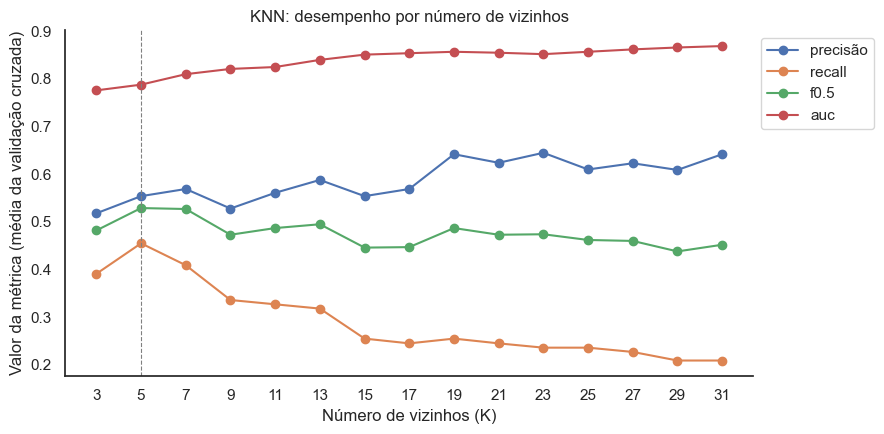

In [43]:
fig, ax = plt.subplots(figsize=(9, 4.5))

for m in ["precisão", "recall", "f0.5", "auc"]:
    ax.plot(resultados_k.index, resultados_k[m], marker="o", label=m)

ax.axvline(melhor_k, color="gray", linestyle="--", linewidth=0.8)
ax.set_xticks(resultados_k.index)
ax.set_xlabel("Número de vizinhos (K)")
ax.set_ylabel("Valor da métrica (média da validação cruzada)")
ax.set_title("KNN: desempenho por número de vizinhos")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
sns.despine()

plt.tight_layout()
plt.savefig("../results/08_knn_escolha_k.png", dpi=150)
plt.show()

**Ajuste do KNN (número de vizinhos)**
- Foram testados valores ímpares de K entre 3 e 31, com validação cruzada no
  conjunto de treino.
- O melhor F0,5 foi obtido com K = 5, valor já utilizado no modelo inicial.
- Valores maiores de K aumentam a precisão e a AUC, mas reduzem fortemente o
  recall (de cerca de 0,45 para 0,20): o modelo passa a identificar poucos
  vinhos de alta qualidade. O F0,5 indica que esse ganho de precisão não
  compensa a perda.
- Mesmo ajustado, o KNN mantém a menor AUC entre os modelos (0,788 com K = 5).

In [44]:
cortes = np.round(np.arange(0.20, 0.81, 0.05), 2)

tabelas_corte = {}
for nome, modelo in modelos_cv.items():
    prob = cross_val_predict(modelo, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]
    linhas_c = []
    for c in cortes:
        pred = (prob >= c).astype(int)
        linhas_c.append({
            "corte": c,
            "precisão": precision_score(y_train, pred, zero_division=0),
            "recall": recall_score(y_train, pred),
            "f0.5": fbeta_score(y_train, pred, beta=0.5, zero_division=0),
            "apostas": pred.sum(),
        })
    tabelas_corte[nome] = pd.DataFrame(linhas_c).set_index("corte").round(3)

for nome, tabela in tabelas_corte.items():
    melhor = tabela["f0.5"].idxmax()
    print(f"{nome}: melhor corte = {melhor} | F0,5 = {tabela.loc[melhor, 'f0.5']} "
          f"(com o corte padrão de 0,5: {tabela.loc[0.5, 'f0.5']})")

Regressão Logística: melhor corte = 0.45 | F0,5 = 0.572 (com o corte padrão de 0,5: 0.551)
KNN: melhor corte = 0.45 | F0,5 = 0.532 (com o corte padrão de 0,5: 0.532)
Random Forest: melhor corte = 0.6 | F0,5 = 0.505 (com o corte padrão de 0,5: 0.464)


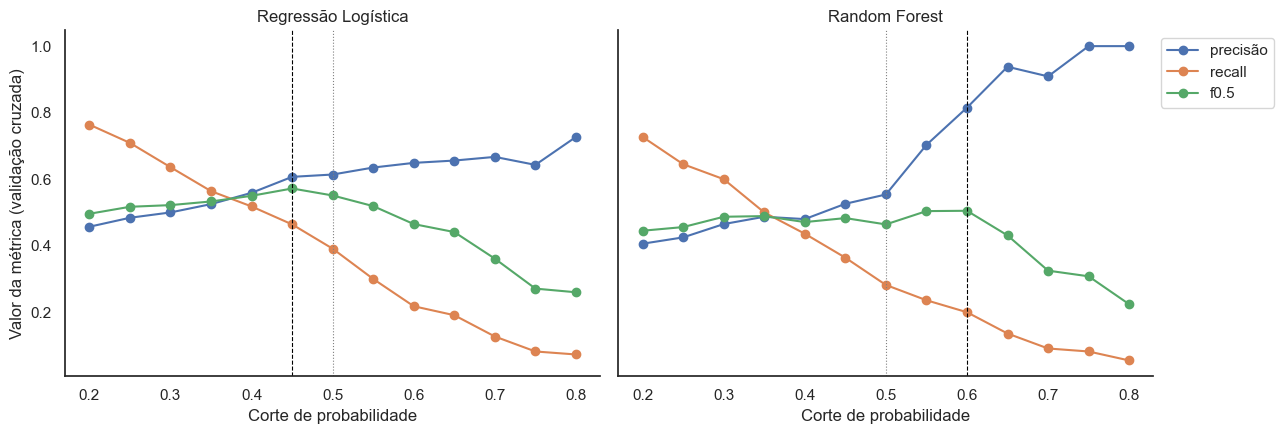

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, nome in zip(axes, ["Regressão Logística", "Random Forest"]):
    t = tabelas_corte[nome]
    for m in ["precisão", "recall", "f0.5"]:
        ax.plot(t.index, t[m], marker="o", label=m)
    ax.axvline(0.5, color="gray", linestyle=":", linewidth=0.8)
    ax.axvline(t["f0.5"].idxmax(), color="black", linestyle="--", linewidth=0.8)
    ax.set_title(nome)
    ax.set_xlabel("Corte de probabilidade")

axes[0].set_ylabel("Valor da métrica (validação cruzada)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
sns.despine()

plt.tight_layout()
plt.savefig("../results/09_ajuste_corte.png", dpi=150)
plt.show()

In [46]:
corte_final = 0.45

prob_final = modelo_lr.predict_proba(X_test_esc)[:, 1]
pred_final = (prob_final >= corte_final).astype(int)

print("Modelo final: Regressão Logística | corte:", corte_final)
print()
print("Precisão:", round(precision_score(y_test, pred_final), 3))
print("Recall:  ", round(recall_score(y_test, pred_final), 3))
print("F0,5:    ", round(fbeta_score(y_test, pred_final, beta=0.5), 3))
print("AUC:     ", round(roc_auc_score(y_test, prob_final), 3))

Modelo final: Regressão Logística | corte: 0.45

Precisão: 0.636
Recall:   0.519
F0,5:     0.609
AUC:      0.886


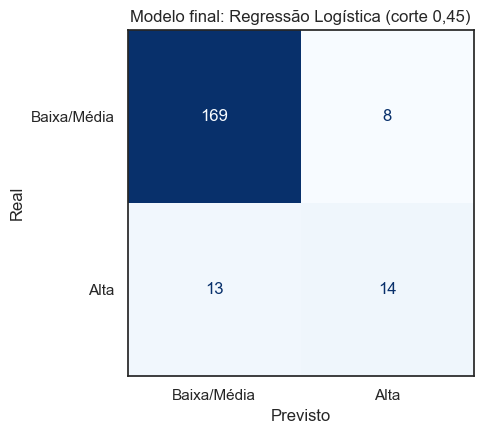

In [47]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final,
    display_labels=["Baixa/Média", "Alta"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Modelo final: Regressão Logística (corte 0,45)")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")

plt.tight_layout()
plt.savefig("../results/10_matriz_confusao_final.png", dpi=150)
plt.show()

**Ajuste de corte e modelo final**
- Os modelos classificam um vinho como de alta qualidade quando a
  probabilidade calculada passa de um corte (padrão de 50%). Foram testados
  cortes de 20% a 80%, com validação cruzada no treino.
- Regressão Logística: o melhor F0,5 foi obtido com corte de 0,45 (0,572,
  contra 0,551 no corte padrão). Subir o corte aumenta pouco a precisão e
  reduz muito o recall.
- Random Forest: com corte de 0,60, a precisão chega a 0,82, mas o modelo
  identifica apenas 20% dos vinhos de alta qualidade. Pode ser uma alternativa
  caso o negócio aceite perder mais vinhos bons para reduzir ainda mais o risco.
- KNN: com 5 vizinhos, as probabilidades variam em degraus de 20%, o que
  limita o ajuste do corte.

**Modelo escolhido: Regressão Logística com corte de 0,45**
- Melhor F0,5 e melhor AUC na validação cruzada, além de ser interpretável.

**Avaliação final no conjunto de teste**
| Métrica | Valor |
|---|---|
| Precisão | 0,636 |
| Recall | 0,519 |
| F0,5 | 0,609 |
| AUC | 0,886 |

- De 22 vinhos indicados como de alta qualidade, 14 de fato eram (63,6%).
  Sem o modelo, a taxa seria de 13,2%, a proporção de vinhos de alta
  qualidade no teste.
- O modelo identificou 14 dos 27 vinhos de alta qualidade (51,9%).

## 6. Interpretação dos resultados

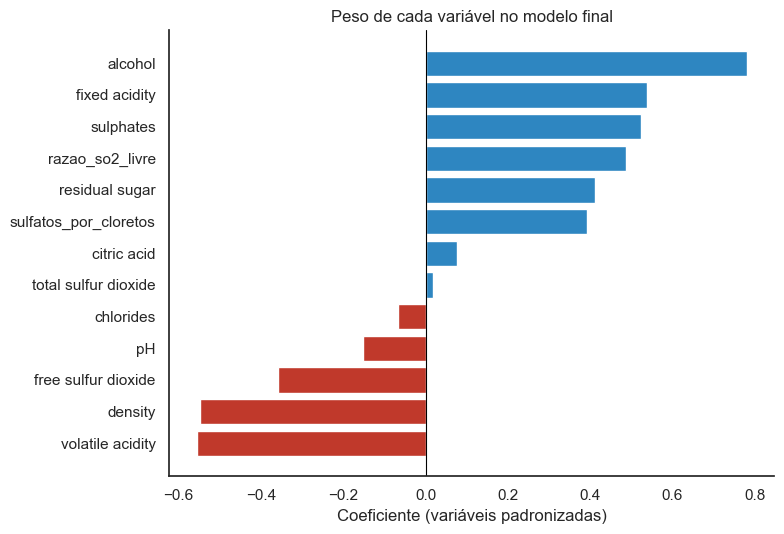

,coeficiente,multiplicador da chance
alcohol,0.78,2.18
fixed acidity,0.54,1.71
sulphates,0.52,1.69
razao_so2_livre,0.49,1.63
residual sugar,0.41,1.51
sulfatos_por_cloretos,0.39,1.48
citric acid,0.08,1.08
total sulfur dioxide,0.02,1.02
chlorides,-0.07,0.94
pH,-0.15,0.86


In [48]:
coeficientes = pd.Series(modelo_lr.coef_[0], index=features_modelo).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
cores = ["#c0392b" if v < 0 else "#2e86c1" for v in coeficientes]
ax.barh(coeficientes.index, coeficientes.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Peso de cada variável no modelo final")
ax.set_xlabel("Coeficiente (variáveis padronizadas)")
sns.despine()

plt.tight_layout()
plt.savefig("../results/11_pesos_modelo_final.png", dpi=150)
plt.show()

pd.DataFrame({
    "coeficiente": coeficientes,
    "multiplicador da chance": np.exp(coeficientes),
}).sort_values("coeficiente", ascending=False).round(2)

**Pesos do modelo final (Regressão Logística)**
- Como as variáveis foram padronizadas, os pesos podem ser comparados entre si.
- Maior influência positiva: `alcohol` (multiplica a chance de alta qualidade
  por 2,2 a cada desvio padrão a mais), seguida de `sulphates` (1,7).
- Maior influência negativa: `volatile acidity` e `density` (reduzem a chance
  para cerca de 0,57 a cada desvio padrão a mais).
- Esses resultados confirmam a EDA para álcool, sulfatos e acidez volátil.
- Algumas variáveis têm peso diferente do que a correlação sugeria:
  `citric acid` tem peso quase nulo, e `fixed acidity` e `residual sugar` têm
  pesos altos. Isso ocorre porque essas variáveis são correlacionadas entre si
  (acidez, pH, densidade e açúcar), e o modelo distribui a influência entre
  elas. Por isso, os pesos dessas variáveis não devem ser interpretados
  isoladamente.

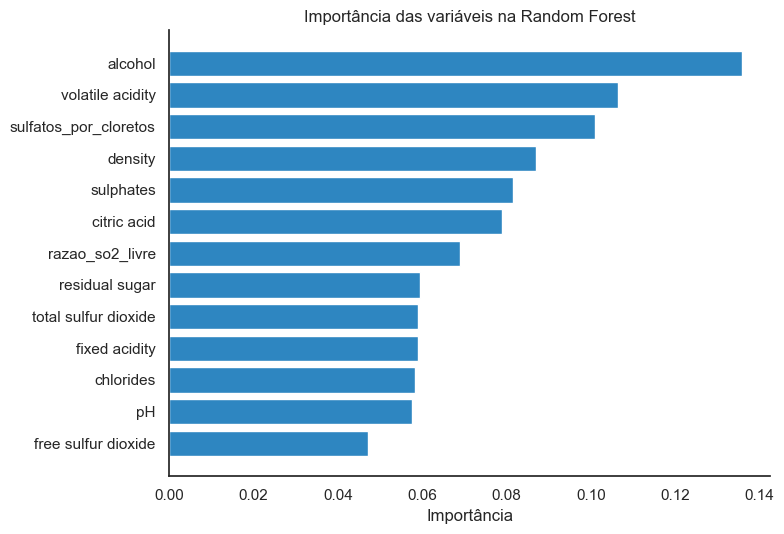

,peso LR (absoluto),ranking LR,importância RF,ranking RF
alcohol,0.780,1,0.136,1
volatile acidity,0.557,2,0.106,2
sulfatos_por_cloretos,0.393,8,0.101,3
density,0.548,3,0.087,4
sulphates,0.523,5,0.082,5
citric acid,0.077,11,0.079,6
razao_so2_livre,0.487,6,0.069,7
residual sugar,0.413,7,0.059,8
total sulfur dioxide,0.019,13,0.059,9
fixed acidity,0.538,4,0.059,10


In [49]:
importancia_rf = pd.Series(modelo_rf.feature_importances_,
                           index=features_modelo).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importancia_rf.index, importancia_rf.values, color="#2e86c1")
ax.set_title("Importância das variáveis na Random Forest")
ax.set_xlabel("Importância")
sns.despine()

plt.tight_layout()
plt.savefig("../results/12_importancia_random_forest.png", dpi=150)
plt.show()

comparacao_imp = pd.DataFrame({
    "peso LR (absoluto)": coeficientes.abs(),
    "ranking LR": coeficientes.abs().rank(ascending=False).astype(int),
    "importância RF": importancia_rf,
    "ranking RF": importancia_rf.rank(ascending=False).astype(int),
}).sort_values("ranking RF").round(3)

comparacao_imp

**Confirmação com a Random Forest**
- Para verificar a robustez da interpretação, a importância das variáveis na
  Random Forest foi comparada aos pesos da Regressão Logística.
- Os dois modelos concordam nas posições de topo: `alcohol` (1º) e
  `volatile acidity` (2º). `density` e `sulphates` também aparecem entre as
  5 mais importantes em ambos. Essas são as conclusões mais confiáveis.
- Há discordância em `fixed acidity` (4º na Regressão Logística, 10º na
  Random Forest), `citric acid` (11º e 6º) e `sulfatos_por_cloretos` (8º e 3º),
  variáveis correlacionadas entre si, cuja influência individual é incerta.
- A partir da 8ª posição, as importâncias na Random Forest são muito próximas
  (entre 0,047 e 0,059), e a ordenação entre elas tem pouco significado.

In [50]:
linhas_feat = []
for nome, modelo in [("Regressão Logística", modelos_cv["Regressão Logística"]),
                     ("Random Forest", modelos_cv["Random Forest"])]:
    for versao, colunas in [("com as novas", features_modelo),
                            ("sem as novas", features)]:
        r = cross_validate(modelo, X_train[colunas], y_train, cv=cv, scoring=metricas)
        linhas_feat.append({
            "modelo": nome,
            "versão": versao,
            "precisão": r["test_precisão"].mean(),
            "f0.5": r["test_f0.5"].mean(),
            "f0.5 (±)": r["test_f0.5"].std(),
            "auc": r["test_auc"].mean(),
        })

pd.DataFrame(linhas_feat).set_index(["modelo", "versão"]).round(3)

precisão   f0.5  f0.5 (±)    auc
modelo              versão                                        
Regressão Logística com as novas     0.618  0.549     0.159  0.888
                    sem as novas     0.618  0.539     0.156  0.887
Random Forest       com as novas     0.564  0.468     0.114  0.867
                    sem as novas     0.592  0.496     0.139  0.869

**Impacto das variáveis criadas (feature engineering)**
- Os modelos foram comparados com e sem `sulfatos_por_cloretos` e
  `razao_so2_livre`, na mesma validação cruzada.
- As diferenças no F0,5 (de 0,010 a 0,028) e na AUC (até 0,002) são muito
  menores que a variação entre as rodadas (±0,11 a ±0,16). As variáveis
  criadas não alteraram o desempenho de forma relevante.
- Embora `sulfatos_por_cloretos` apareça como a 3ª variável mais importante na
  Random Forest, ela resume informação que `sulphates` e `chlorides` já
  continham: sem ela, o modelo usa as variáveis originais e chega ao mesmo
  resultado.
- As variáveis foram mantidas no modelo final, pois não prejudicam o
  desempenho e o modelo já havia sido avaliado com elas no conjunto de teste.

## Implicações para a produção

**1. Uso do modelo: triagem de vinhos premium**
- O modelo pode ser usado como uma triagem a partir das análises de
  laboratório: ele indica quais lotes têm maior chance de serem de alta
  qualidade, para que sejam priorizados na avaliação sensorial.
- Sem o modelo, 13% dos vinhos são de alta qualidade. Entre os vinhos que o
  modelo indica, 64% são. Isso reduz o tempo de degustação gasto com vinhos
  comuns.
- O modelo não substitui a avaliação de especialistas: ele identifica cerca de
  metade dos vinhos de alta qualidade, e 4 em cada 10 indicações não se
  confirmam.

**2. O que mais se associa a vinhos de alta qualidade**
As conclusões mais confiáveis, confirmadas na EDA e nos dois modelos:
- **Teor alcoólico mais alto** está associado a vinhos de alta qualidade.
- **Acidez volátil mais baixa** também. Em excesso, ela deixa o vinho com
  sabor avinagrado.
- **Sulfatos mais altos** estão associados à qualidade. Eles atuam na
  conservação do vinho.

**3. Recomendações para a produção (hipóteses a testar)**
- Monitorar o teor alcoólico, que depende da maturação da uva no momento da
  colheita.
- Controlar a acidez volátil durante a fermentação e o armazenamento, como
  um indicador de alerta de qualidade.
- Acompanhar os níveis de sulfatos dentro dos limites permitidos.
- Como os dados mostram associação e não causa, essas mudanças devem ser
  testadas em lotes controlados antes de serem adotadas em toda a produção.

**4. Limitações**
- A base tem apenas 1.018 vinhos distintos e 137 de alta qualidade, o que
  torna as métricas sensíveis a poucos acertos ou erros.
- A nota de qualidade vem de avaliações sensoriais, que têm um componente
  subjetivo.
- As variáveis disponíveis são apenas físico-químicas. Fatores como tipo de
  uva, safra e região não estão na base e podem influenciar a qualidade.
- Variáveis correlacionadas entre si (acidez, pH, densidade e açúcar) não
  permitem separar o efeito individual de cada uma.

In [51]:
resultados.to_csv("../results/metricas_teste_inicial.csv")
resultados_cv.to_csv("../results/metricas_validacao_cruzada.csv")
print("Métricas salvas em results/")

Métricas salvas em results/
